# Reconocimiento de enfermedades en hojas de frijol mediante imágenes
**Mauricio Guerrero González A01751436**

## 1. Introducción
En este proyecto se busca reconocer el estado de una hoja de frijol a partir de una fotografía; para ello, se comparan dos modelos de aprendizaje profundo que clasifican las imágenes en tres categorías: mancha angular, roya del frijol y hoja sana. La idea es analizar si una red neuronal puede identificar patrones visuales útiles, como cambios de color o lesiones, y así apoyar la revisión de los cultivos.

El problema resulta relevante porque una revisión visual puede ser difícil cuando las hojas tienen síntomas parecidos; sin embargo, el modelo se plantea como un ejercicio de clasificación y no como un diagnóstico definitivo para tomar decisiones agrícolas. Además, se trabaja con fotografías reales tomadas en campo, por lo que existen diferencias de iluminación, posición y fondo que hacen que el problema sea más cercano a una situación real.

Para desarrollar la solución, primero se entrena una CNN desde cero y después se prueba una red preentrenada con regularización; posteriormente, se selecciona la mejor alternativa mediante validación y se evalúa una sola vez con el conjunto de prueba. Se utiliza F1 macro como criterio principal, ya que considera por igual las tres clases; además, se reporta accuracy para conocer la proporción de imágenes clasificadas correctamente.

### Preparación del entorno
Primero se importan las bibliotecas que se utilizarán y se fija una semilla para facilitar la reproducción; además, se prepara una carpeta temporal donde se guardarán las descargas.

In [ ]:
import os
from pathlib import Path
RAIZ = Path.cwd()
TRABAJO = RAIZ / 'datos'
TRABAJO.mkdir(exist_ok=True)
os.environ['KERAS_HOME'] = str(TRABAJO / 'keras_cache')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import json, hashlib, zipfile, urllib.request, shutil, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

SEMILLA = 42
TAMANO = 128
LOTE = 32
CLASES = ['Mancha angular', 'Roya del frijol', 'Hoja sana']
CARPETAS = ['angular_leaf_spot', 'bean_rust', 'healthy']
keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', platform.python_version(), '| TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('Semilla:', SEMILLA, '| Tamaño de entrada:', (TAMANO, TAMANO, 3))
print('GPU disponibles:', len(tf.config.list_physical_devices('GPU')))

Python: 3.12.14 | TensorFlow: 2.21.0 | Keras: 3.15.1
Semilla: 42 | Tamaño de entrada: (128, 128, 3)


GPU disponibles: 0


## 2. Datos
Se utiliza el conjunto Beans, elaborado por Makerere AI Lab; contiene 1 295 fotografías de hojas de frijol tomadas en campo con teléfonos y etiquetadas por especialistas.

Los archivos ya están separados en 1 034 imágenes de entrenamiento, 133 de validación y 128 de prueba; se conserva esta división para que la selección del modelo no dependa de los resultados finales. Las categorías originales son `angular_leaf_spot`, `bean_rust` y `healthy`, en el cuaderno se manejan en español.

La fuente del proyecto es [Makerere AI Lab, Bean disease dataset, 2020](https://github.com/AI-Lab-Makerere/ibean)


In [ ]:
HUELLAS = {
    'train': '284fe8456ce20687f4367ae7ad94a64577e7f9fde2c2c6b1c74340ab5dc82715',
    'validation': '90b7aa1c26d91d9afff07a30bbc67a5ea34f1f1397f068d8675be09d7d0c602d',
    'test': 'ca67b15d960d1e2fd9d23fd8498ce86818ead90755c630a43baf19ec4af09312'
}
for particion, huella in HUELLAS.items():
    archivo = TRABAJO / f'{particion}.zip'
    url = f'https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/main/data/{particion}.zip'
    if not archivo.exists():
        solicitud = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(solicitud, timeout=180) as respuesta, archivo.open('wb') as salida:
            shutil.copyfileobj(respuesta, salida)
    assert hashlib.sha256(archivo.read_bytes()).hexdigest() == huella, 'La descarga no coincide con la versión revisada'
    if not (TRABAJO / particion).exists():
        with zipfile.ZipFile(archivo) as comprimido:
            for entrada in comprimido.infolist():
                destino = (TRABAJO / entrada.filename).resolve()
                if not destino.is_relative_to(TRABAJO.resolve()):
                    raise ValueError('Se encontró una ruta no permitida en la descarga')
            comprimido.extractall(TRABAJO)
    print(particion, '| Descarga íntegra:', round(archivo.stat().st_size / 1e6, 2), 'MB')

train | Descarga íntegra: 143.81 MB
validation | Descarga íntegra: 18.5 MB


test | Descarga íntegra: 17.71 MB


Se construye una tabla con la ruta, la clase y la partición de cada imagen; además, se verifica que las fotografías se puedan abrir y que no se repitan exactamente entre los conjuntos.

In [ ]:
filas = []
for particion in HUELLAS:
    for etiqueta, categoria in enumerate(CARPETAS):
        for ruta in sorted((TRABAJO / particion / categoria).glob('*.jpg')):
            with Image.open(ruta) as imagen:
                imagen.load()
                rgb = np.asarray(imagen.convert('RGB'))
                filas.append({'ruta': str(ruta), 'particion': particion, 'etiqueta': etiqueta,
                              'clase': CLASES[etiqueta], 'ancho': imagen.width, 'alto': imagen.height,
                              'hash_pixeles': hashlib.sha256(rgb.tobytes()).hexdigest()})
datos = pd.DataFrame(filas)
assert datos.groupby('particion').size().to_dict() == {'test': 128, 'train': 1034, 'validation': 133}
cruces = datos.groupby('hash_pixeles').particion.nunique()
assert (cruces <= 1).all(), 'Hay imágenes idénticas entre particiones; revisar antes de entrenar'
display(pd.crosstab(datos.clase, datos.particion).reindex(CLASES)[['train', 'validation', 'test']])
display(datos[['ancho', 'alto']].describe().round(1))
print('Imágenes revisadas:', len(datos), '| Valores faltantes:', int(datos.isna().sum().sum()))
print('Duplicados exactos entre particiones:', int((cruces > 1).sum()))
print('Duplicados exactos dentro de particiones:', int(datos.duplicated(['particion', 'hash_pixeles']).sum()))

particion,train,validation,test
clase,,,
Mancha angular,345,44,43
Roya del frijol,348,45,43
Hoja sana,341,44,42


,ancho,alto
count,1295.0,1295.0
mean,500.0,500.0
std,0.0,0.0
min,500.0,500.0
25%,500.0,500.0
50%,500.0,500.0
75%,500.0,500.0
max,500.0,500.0


Imágenes revisadas: 1295 | Valores faltantes: 0
Duplicados exactos entre particiones: 0
Duplicados exactos dentro de particiones: 0


Se revisa la distribución de clases y se muestran ejemplos de entrenamiento; de esta forma, se observa tanto el equilibrio de las categorías como las diferencias visuales que tendrá que aprender el modelo.

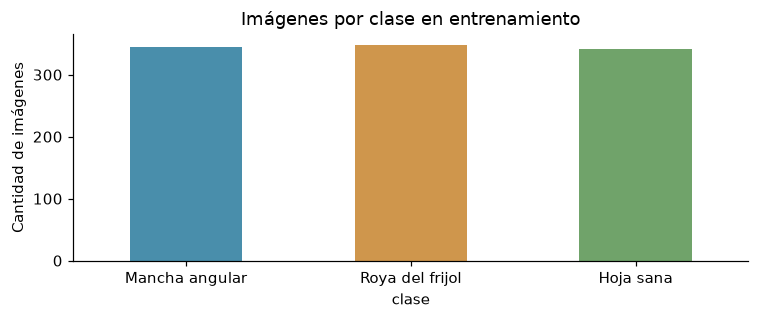

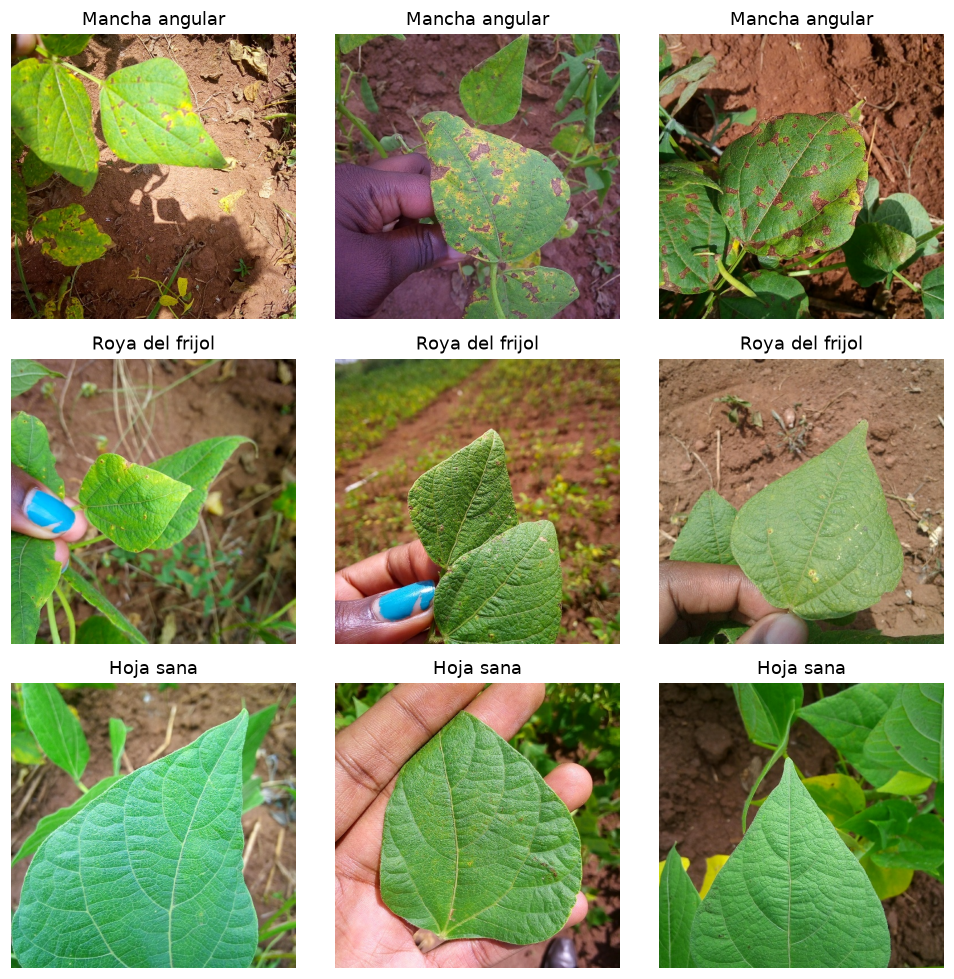

La clase mayoritaria representa 33.66% del entrenamiento


In [ ]:
entrenamiento = datos[datos.particion == 'train']
conteos = entrenamiento.clase.value_counts().reindex(CLASES)
fig, ax = plt.subplots(figsize=(7, 3))
conteos.plot.bar(ax=ax, color=['#498eab', '#cf964c', '#70a36a'], rot=0)
ax.set(title='Imágenes por clase en entrenamiento', ylabel='Cantidad de imágenes')
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for etiqueta in range(3):
    ejemplos = entrenamiento[entrenamiento.etiqueta == etiqueta].iloc[:3]
    for ax, ruta in zip(axes[etiqueta], ejemplos.ruta):
        with Image.open(ruta) as foto:
            ax.imshow(foto.convert('RGB'))
        ax.set_title(CLASES[etiqueta])
        ax.axis('off')
fig.tight_layout()
plt.show()
print(f'La clase mayoritaria representa {conteos.max() / conteos.sum():.2%} del entrenamiento')

Las tres clases tienen cantidades similares, por lo que no se aplican pesos de clase; además, los ejemplos permiten observar que el fondo y la iluminación también cambian entre fotografías. Esto es importante porque el modelo podría aprender características del entorno en lugar de síntomas de la hoja; por ello, una buena clasificación dentro del dataset no sustituye una prueba en otras condiciones.

Se preparan las imágenes en RGB y se ajustan a 128 por 128 píxeles; asimismo, se conserva el rango de 0 a 255, ya que cada arquitectura aplicará internamente su propia normalización.

In [ ]:
def leer_imagen(ruta):
    with Image.open(ruta) as imagen:
        imagen = ImageOps.exif_transpose(imagen).convert('RGB')
        imagen = imagen.resize((TAMANO, TAMANO), Image.Resampling.BILINEAR)
        return np.asarray(imagen, dtype=np.float32)

def cargar(particion):
    tabla = datos[datos.particion == particion].reset_index(drop=True)
    x = np.stack([leer_imagen(ruta) for ruta in tabla.ruta])
    y = tabla.etiqueta.to_numpy(dtype=np.int32)
    assert np.isfinite(x).all() and x.shape[1:] == (128, 128, 3)
    return x, y, tabla

X_train, y_train, tabla_train = cargar('train')
X_val, y_val, tabla_val = cargar('validation')
X_test, y_test, tabla_test = cargar('test')
for nombre, x, y in [('Entrenamiento', X_train, y_train), ('Validación', X_val, y_val), ('Prueba reservada', X_test, y_test)]:
    print(nombre, '| Forma:', x.shape, '| Rango:', (x.min(), x.max()))
referencia = np.full_like(y_val, np.bincount(y_train).argmax())
print(f'Referencia mayoritaria en validación: accuracy={accuracy_score(y_val, referencia):.4f}; F1 macro={f1_score(y_val, referencia, average="macro"):.4f}')

Entrenamiento | Forma: (1034, 128, 128, 3) | Rango: (np.float32(0.0), np.float32(255.0))
Validación | Forma: (133, 128, 128, 3) | Rango: (np.float32(0.0), np.float32(255.0))
Prueba reservada | Forma: (128, 128, 128, 3) | Rango: (np.float32(0.0), np.float32(255.0))
Referencia mayoritaria en validación: accuracy=0.3383; F1 macro=0.1685


## 3. Desarrollo del modelo
Como punto de partida se construye una CNN con tres capas `Conv2D`, de 16, 32 y 64 filtros; cada bloque utiliza una activación ReLU y una capa de pooling para reducir el tamaño de las representaciones. Después se aplica un promedio global y una capa densa; finalmente, una salida softmax devuelve las puntuaciones de las tres categorías.

Se utiliza Adam con una tasa de aprendizaje de 0.001 y entropía cruzada para etiquetas enteras; además, el entrenamiento tiene un máximo de 25 épocas y se detiene si la pérdida de validación deja de mejorar durante seis épocas. Igualmente se recuperan los pesos de la mejor época, de modo que no se elige automáticamente la última; el conjunto de prueba permanece fuera de este proceso.

Posteriormente se define la CNN inicial y se muestra su arquitectura; además, se prepara una función para registrar sus métricas de validación y otra para visualizar el comportamiento durante el entrenamiento.

In [ ]:
keras.utils.set_random_seed(SEMILLA)
inicial = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),
    keras.layers.Rescaling(1. / 255),
    keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
    keras.layers.MaxPooling2D(),
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(3, activation='softmax')
], name='cnn_inicial')
inicial.compile(optimizer=keras.optimizers.Adam(0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
inicial.summary()
registros = []

def medir_validacion(nombre, modelo):
    p = modelo.predict(X_val, verbose=0)
    perdida = float(np.mean(keras.losses.sparse_categorical_crossentropy(y_val, p)))
    fila = {'modelo': nombre, 'val_loss': perdida,
            'val_accuracy': accuracy_score(y_val, p.argmax(axis=1)),
            'val_f1_macro': f1_score(y_val, p.argmax(axis=1), average='macro')}
    registros.append(fila)
    display(pd.DataFrame([fila]).round(4))

def curvas(historia, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, metrica, nombre in zip(axes, ['loss', 'accuracy'], ['Pérdida', 'Accuracy']):
        epocas = np.arange(1, len(historia.history[metrica]) + 1)
        ax.plot(epocas, historia.history[metrica], label='Entrenamiento')
        ax.plot(epocas, historia.history['val_' + metrica], label='Validación')
        ax.set(xlabel='Época', ylabel=nombre, title=f'{titulo}: {nombre}')
        ax.legend()
    fig.tight_layout()
    plt.show()

Model: "cnn_inicial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,763 (100.64 KB)

 Trainable params: 25,763 (100.64 KB)

 Non-trainable params: 0 (0.00 B)

Se entrena la primera red y se revisa su desempeño en validación; posteriormente, se muestran las curvas para identificar si el aprendizaje se estabiliza o si aparece una diferencia creciente entre entrenamiento y validación.

Epoch 1/25


33/33 - 6s - 172ms/step - accuracy: 0.3762 - loss: 1.0956 - val_accuracy: 0.3835 - val_loss: 1.0763


Epoch 2/25


33/33 - 5s - 140ms/step - accuracy: 0.4923 - loss: 1.0412 - val_accuracy: 0.5338 - val_loss: 0.9643


Epoch 3/25


33/33 - 5s - 139ms/step - accuracy: 0.5725 - loss: 0.9324 - val_accuracy: 0.5564 - val_loss: 0.8896


... (41 outputs left out)

33/33 - 5s - 138ms/step - accuracy: 0.7485 - loss: 0.6068 - val_accuracy: 0.7368 - val_loss: 0.5598


Epoch 25/25


33/33 - 5s - 147ms/step - accuracy: 0.7563 - loss: 0.5972 - val_accuracy: 0.7444 - val_loss: 0.5533


,modelo,val_loss,val_accuracy,val_f1_macro
0,CNN inicial,0.5533,0.7444,0.7378


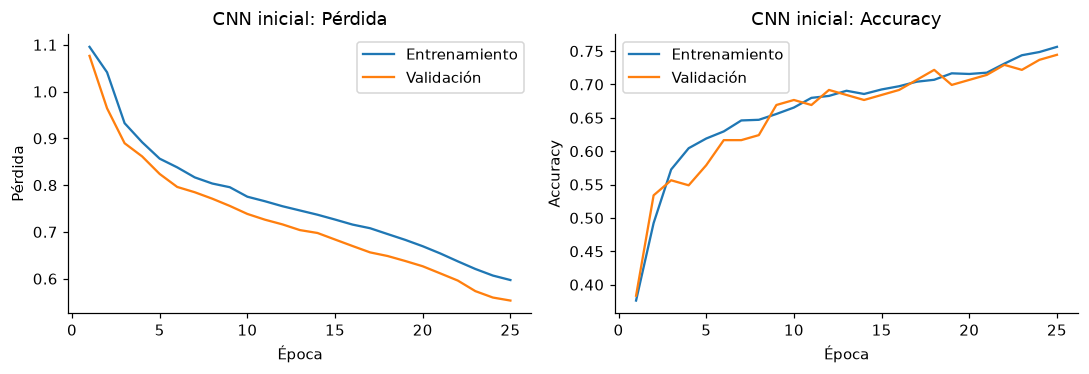

Mejor época por pérdida: 25
Brecha de accuracy en esa época: 0.0119


In [ ]:
historia_inicial = inicial.fit(
    X_train, y_train, validation_data=(X_val, y_val), epochs=25, batch_size=LOTE,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)],
    verbose=2
)
medir_validacion('CNN inicial', inicial)
curvas(historia_inicial, 'CNN inicial')
mejor_epoca = int(np.argmin(historia_inicial.history['val_loss']))
print('Mejor época por pérdida:', mejor_epoca + 1)
print(f'Brecha de accuracy en esa época: {historia_inicial.history["accuracy"][mejor_epoca] - historia_inicial.history["val_accuracy"][mejor_epoca]:.4f}')

## 4. Ajuste del modelo
Para mejorar el punto de partida se prueba MobileNetV2, una red convolucional preentrenada con ImageNet; la idea es aprovechar características visuales que ya fueron aprendidas con muchas imágenes, en lugar de intentar aprenderlas todas con las 1 034 fotografías disponibles. La base se mantiene congelada y se entrena una nueva capa de clasificación; además, se añade Dropout de 0.35 para reducir la dependencia de algunas activaciones.

La nueva cabeza tiene 128 unidades, regularización L2 de 0.0001 y una tasa de aprendizaje de 0.001; se permiten hasta 40 épocas, con detención temprana después de siete épocas sin mejora. Esta iteración cambia la arquitectura y la regularización de manera conjunta, por lo que no permite atribuir la diferencia a una sola técnica; el propósito es comparar una solución inicial con una alternativa más adecuada para pocos datos. Como la base convolucional no se actualiza, se calculan sus características una sola vez para entrenamiento y validación; esto reduce el tiempo de ejecución sin cambiar la función que se entrena. Al final se unen la normalización, la base y la cabeza en un solo modelo que recibe imágenes.

Se carga MobileNetV2 y se congelan sus pesos; después se extraen las características de entrenamiento y validación, manteniendo la prueba fuera de la selección del modelo.

In [ ]:
keras.utils.set_random_seed(SEMILLA)
base = keras.applications.MobileNetV2(input_shape=(128, 128, 3), include_top=False, weights='imagenet', pooling='avg')
# Conserva los pesos preentrenados durante el ajuste de la cabeza.
base.trainable = False
entrada = keras.Input(shape=(128, 128, 3), name='imagen_rgb')
normalizada = keras.layers.Rescaling(1. / 127.5, offset=-1, name='normalizacion')(entrada)
representacion = base(normalizada, training=False)
extractor = keras.Model(entrada, representacion, name='extractor_mobilenet')
F_train = extractor.predict(X_train, batch_size=LOTE, verbose=0)
F_val = extractor.predict(X_val, batch_size=LOTE, verbose=0)
print('Características de entrenamiento:', F_train.shape)
print('Características de validación:', F_val.shape)
print('Parámetros de la base:', base.count_params(), '| Variables entrenables de la base:', len(base.trainable_weights))

      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

 311296/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

1179648/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

2195456/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

3112960/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

4210688/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

5423104/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

6684672/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

8060928/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Características de entrenamiento: (1034, 1280)
Características de validación: (133, 1280)
Parámetros de la base: 2257984 | Variables entrenables de la base: 0


Se entrena la nueva cabeza con Dropout y regularización; una vez recuperados los mejores pesos, se conecta con la base convolucional para evaluar el modelo completo sobre las imágenes de validación.

Epoch 1/40


33/33 - 1s - 26ms/step - accuracy: 0.6963 - loss: 0.7684 - val_accuracy: 0.8346 - val_loss: 0.3821


Epoch 2/40


33/33 - 0s - 3ms/step - accuracy: 0.8665 - loss: 0.3692 - val_accuracy: 0.8797 - val_loss: 0.3052


Epoch 3/40


33/33 - 0s - 4ms/step - accuracy: 0.9091 - loss: 0.2652 - val_accuracy: 0.9173 - val_loss: 0.2613


... (31 outputs left out)

33/33 - 0s - 3ms/step - accuracy: 0.9971 - loss: 0.0433 - val_accuracy: 0.9173 - val_loss: 0.2837


Epoch 20/40


33/33 - 0s - 4ms/step - accuracy: 0.9952 - loss: 0.0422 - val_accuracy: 0.9023 - val_loss: 0.2567


,modelo,val_loss,val_accuracy,val_f1_macro
0,MobileNetV2 ajustado,0.1641,0.9173,0.9174


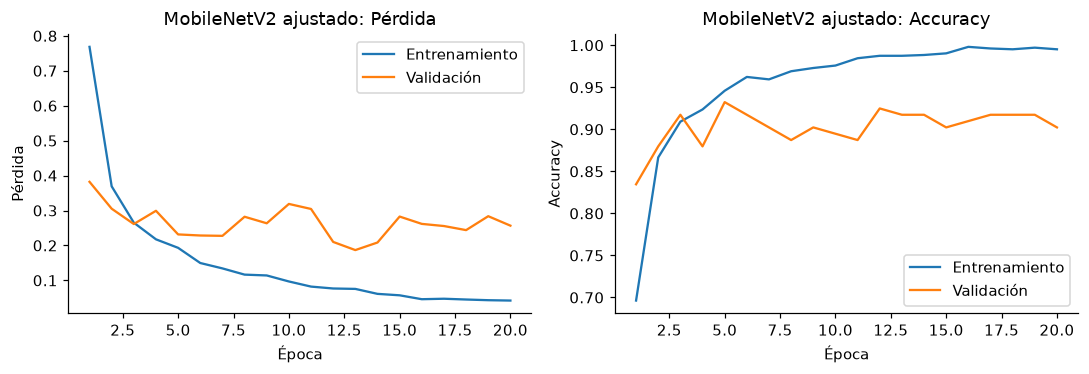

Model: "mobilenet_ajustado"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_rgb (InputLayer)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacion (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clasificador (Sequential)       │ (None, 3)              │       164,355 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Mejor época de la cabeza: 13


In [ ]:
cabeza = keras.Sequential([
    keras.Input(shape=(F_train.shape[1],)),
    keras.layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l2(0.0001)),
    keras.layers.Dropout(0.35, seed=SEMILLA),
    keras.layers.Dense(3, activation='softmax')
], name='clasificador')
cabeza.compile(optimizer=keras.optimizers.Adam(0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
historia_ajuste = cabeza.fit(
    F_train, y_train, validation_data=(F_val, y_val), epochs=40, batch_size=LOTE,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)],
    verbose=2
)
ajustado = keras.Model(entrada, cabeza(representacion), name='mobilenet_ajustado')
medir_validacion('MobileNetV2 ajustado', ajustado)
curvas(historia_ajuste, 'MobileNetV2 ajustado')
ajustado.summary()
print('Mejor época de la cabeza:', int(np.argmin(historia_ajuste.history['val_loss'])) + 1)

Se comparan las dos propuestas mediante F1 macro de validación; además, se explica si el ajuste funcionó y se guarda únicamente el modelo seleccionado, con su arquitectura y sus pesos.

In [ ]:
comparacion = pd.DataFrame(registros)
display(comparacion.round(4))
seleccion = comparacion.sort_values(['val_f1_macro', 'val_loss'], ascending=[False, True], kind='stable').iloc[0]
nombre_final = seleccion['modelo']
modelo_final = ajustado if nombre_final == 'MobileNetV2 ajustado' else inicial
# Selecciona el modelo únicamente con los resultados de validación.
modelo_final.save(RAIZ / 'modelo_final.keras')
delta = registros[1]['val_f1_macro'] - registros[0]['val_f1_macro']
interpretacion = (
    'La mejora es compatible con la utilidad de las características preentrenadas y de la regularización cuando hay pocas imágenes; '
    'sin embargo, como ambos cambios se aplicaron juntos, no se puede afirmar cuánto aportó cada uno.'
    if delta > 0 else
    'El ajuste no superó el F1 macro inicial en esta partición; por ello, no se presenta como una mejora y se conserva la alternativa con mejor validación.'
)
display(Markdown(f'El cambio de F1 macro fue de **{delta * 100:+.2f} puntos porcentuales**; por lo tanto, se seleccionó **{nombre_final}**, con un F1 de **{seleccion["val_f1_macro"]:.4f}**. {interpretacion}'))
print('Archivo guardado:', 'modelo_final.keras')

,modelo,val_loss,val_accuracy,val_f1_macro
0,CNN inicial,0.5533,0.7444,0.7378
1,MobileNetV2 ajustado,0.1641,0.9173,0.9174


El cambio de F1 macro fue de **+17.96 puntos porcentuales**; por lo tanto, se seleccionó **MobileNetV2 ajustado**, con un F1 de **0.9174**. La mejora es compatible con la utilidad de las características preentrenadas y de la regularización cuando hay pocas imágenes; sin embargo, como ambos cambios se aplicaron juntos, no se puede afirmar cuánto aportó cada uno.

Archivo guardado: modelo_final.keras


Al interpretar las curvas también debe considerarse que Dropout está activo durante el entrenamiento y desactivado al validar; por ello, una validación mejor que el entrenamiento no implica automáticamente un error. Además, la pérdida de la cabeza incluye el término L2, mientras que la tabla comparativa utiliza únicamente entropía cruzada para ambos modelos; así se evita comparar pérdidas que incluyen penalizaciones distintas.

## 5. Resultados
Una vez tomada la decisión con validación, se utiliza la partición de prueba para medir el desempeño final; a partir de este punto no se cambia el modelo según sus errores. Se revisan accuracy, F1 macro, precisión y sensibilidad por clase; además, una matriz de confusión permite identificar qué categorías se confunden con mayor frecuencia.

La prueba contiene 128 imágenes, por lo que unos pocos errores pueden modificar de forma visible las métricas; por esta razón, los resultados describen esta partición y no deben interpretarse como una garantía para cualquier fotografía. También se conserva la limitación de no conocer la planta o parcela de origen de cada imagen.

Se evalúa el modelo seleccionado con las imágenes de prueba; después se muestran las métricas generales y el reporte por clase para distinguir el resultado promedio de las dificultades de cada categoría.

In [ ]:
prob_test = modelo_final.predict(X_test, batch_size=LOTE, verbose=0)
pred_test = prob_test.argmax(axis=1)
metricas = {'modelo': nombre_final, 'accuracy': accuracy_score(y_test, pred_test),
            'f1_macro': f1_score(y_test, pred_test, average='macro'),
            'imagenes_prueba': len(y_test)}
display(pd.DataFrame([metricas]).round(4))
reporte = pd.DataFrame(classification_report(y_test, pred_test, labels=[0, 1, 2],
                      target_names=CLASES, output_dict=True, zero_division=0)).T
display(reporte.round(4))
print('Aciertos:', int((pred_test == y_test).sum()), '| Errores:', int((pred_test != y_test).sum()))

,modelo,accuracy,f1_macro,imagenes_prueba
0,MobileNetV2 ajustado,0.8984,0.8987,128


,precision,recall,f1-score,support
Mancha angular,0.8511,0.9302,0.8889,43.0000
Roya del frijol,0.8750,0.8140,0.8434,43.0000
Hoja sana,0.9756,0.9524,0.9639,42.0000
accuracy,0.8984,0.8984,0.8984,0.8984
macro avg,0.9006,0.8989,0.8987,128.0000
weighted avg,0.9000,0.8984,0.8982,128.0000


Aciertos: 115 | Errores: 13


Se muestran las confusiones entre categorías y algunos errores reales; así se puede revisar el resultado directamente en las fotografías, sin seleccionar únicamente ejemplos que el modelo acertó.

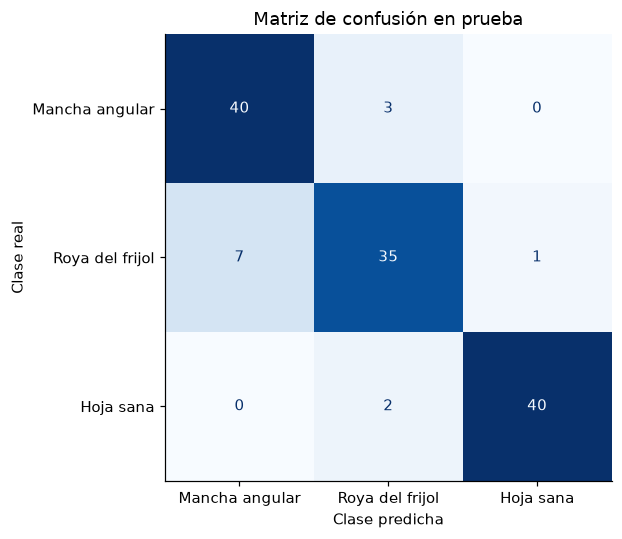

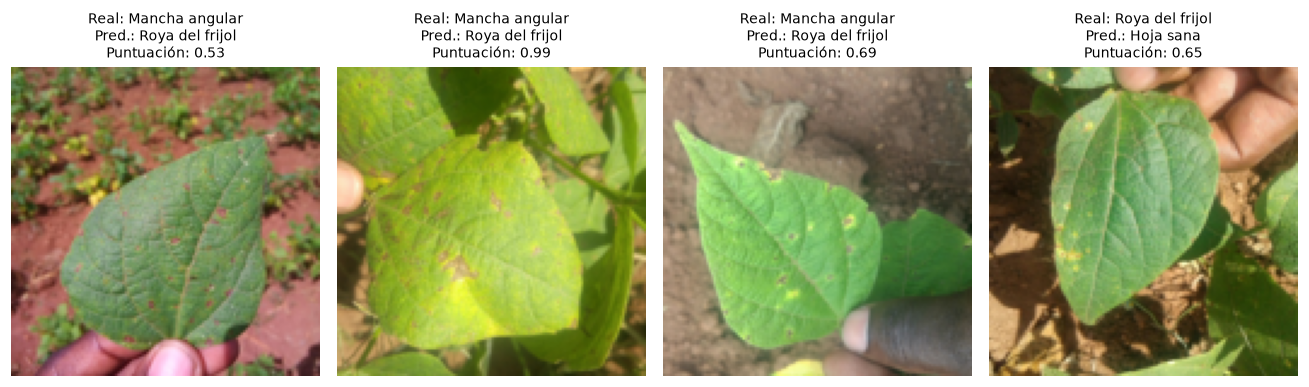

La confusión más frecuente fue de **Roya del frijol** hacia **Mancha angular**, con **7 imágenes**; las fotografías permiten revisar posibles similitudes visuales, aunque no demuestran por sí solas la causa del error.

In [ ]:
matriz = confusion_matrix(y_test, pred_test, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matriz, display_labels=CLASES).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set(title='Matriz de confusión en prueba', xlabel='Clase predicha', ylabel='Clase real')
fig.tight_layout()
plt.show()
errores = np.flatnonzero(pred_test != y_test)
if len(errores):
    fig, axes = plt.subplots(1, min(4, len(errores)), figsize=(12, 3.6), squeeze=False)
    for ax, indice in zip(axes.flat, errores[:4]):
        ax.imshow(X_test[indice].astype(np.uint8))
        ax.set_title(chr(10).join([f'Real: {CLASES[y_test[indice]]}', f'Pred.: {CLASES[pred_test[indice]]}', f'Puntuación: {prob_test[indice].max():.2f}']), fontsize=9)
        ax.axis('off')
    fig.tight_layout()
    plt.show()
else:
    print('No se encontraron errores en esta partición')
fuera_diagonal = matriz.copy()
np.fill_diagonal(fuera_diagonal, 0)
a, b = np.unravel_index(fuera_diagonal.argmax(), fuera_diagonal.shape)
if fuera_diagonal.max() > 0:
    display(Markdown(f'La confusión más frecuente fue de **{CLASES[a]}** hacia **{CLASES[b]}**, con **{fuera_diagonal[a, b]} imágenes**; las fotografías permiten revisar posibles similitudes visuales, aunque no demuestran por sí solas la causa del error.'))

## 6. Conclusiones

El modelo seleccionado fue MobileNetV2 ajustado; en la prueba obtuvo 89.84 % de accuracy y 0.8987 de F1 macro, considerando 128 fotografías que no se utilizaron para entrenar ni seleccionar la arquitectura.

El ajuste mejoró el F1 macro de validación en 17.96 puntos porcentuales respecto a la CNN inicial; este resultado es compatible con la utilidad de las características preentrenadas y de la regularización cuando se dispone de pocas imágenes. Sin embargo, como ambos cambios se aplicaron juntos, no se puede afirmar cuánto aportó cada uno; por su parte, la clase con menor F1 en prueba fue Roya del frijol, con 0.8434, lo que permite identificar dónde conviene concentrar la revisión de errores.

Cabe destacar que a pesar de que las imágenes son reales, el conjunto es pequeño y proviene de un contexto específico; además, no se comprobó la independencia por planta o parcela ni la ausencia de fotografías visualmente similares. Por lo tanto, el resultado no demuestra que el modelo mantenga su desempeño con otras regiones, cámaras o condiciones de iluminación.

Como siguiente paso, se podría recopilar un conjunto de prueba externo, repetir los experimentos con varias semillas y estudiar el aumento de datos o el ajuste fino de las últimas capas de MobileNetV2; estas decisiones deberían evaluarse mediante validación, conservando una prueba nueva para la evaluación final. Asimismo, sería útil incluir imágenes que no correspondan a hojas de frijol, ya que el modelo actual siempre elige una de las tres categorías y no cuenta con una clase de rechazo.


## 7. Aplicación
Para probar el modelo se implementa una función que recibe la ruta de una imagen JPG o PNG y devuelve la categoría predicha; además, muestra las puntuaciones de las tres clases para facilitar la revisión. La función convierte la fotografía a RGB y utiliza el mismo tamaño aplicado al entrenar; por su parte, la normalización ya se encuentra dentro del modelo guardado.

Los ejemplos de la demostración se toman de la prueba y son nuevos respecto al entrenamiento; no se presentan como fotografías recolectadas de manera independiente. Para usar una imagen propia, basta con llamar a `predecir_imagen('ruta/a/mi_fotografia.jpg')`; debe tratarse de una hoja de frijol en condiciones parecidas a las del dataset.

Para este último paso únicamente se carga el archivo `.keras` y se define la función de predicción; asimismo, se comprueba que el modelo recargado produzca las mismas salidas que el modelo evaluado antes de guardarlo.

In [ ]:
modelo_cargado = keras.models.load_model(RAIZ / 'modelo_final.keras', compile=False)

def predecir_imagen(ruta_imagen, mostrar=True):
    ruta = Path(ruta_imagen)
    if not ruta.is_file():
        raise FileNotFoundError(f'No se encontró la fotografía: {ruta}')
    try:
        imagen = leer_imagen(ruta)
    except (OSError, ValueError) as error:
        raise ValueError('El archivo no es una imagen compatible') from error
    probabilidades = modelo_cargado.predict(imagen[None, ...], verbose=0)[0]
    resultado = {'clase': CLASES[int(probabilidades.argmax())],
                 'puntuacion': float(probabilidades.max()),
                 'puntuaciones': dict(zip(CLASES, map(float, probabilidades)))}
    if mostrar:
        fig, ax = plt.subplots(figsize=(4, 4))
        ax.imshow(imagen.astype(np.uint8))
        ax.set_title(f'{resultado["clase"]} | puntuación: {resultado["puntuacion"]:.3f}')
        ax.axis('off')
        plt.show()
        display(pd.DataFrame([resultado['puntuaciones']]).round(4))
    return resultado

# Comprueba que el archivo entregado conserva las predicciones del modelo.
np.testing.assert_allclose(modelo_cargado.predict(X_test[:6], verbose=0), prob_test[:6], rtol=1e-5, atol=1e-6)
print('Modelo recargado correctamente; arquitectura y pesos conservados en modelo_final.keras')

Modelo recargado correctamente; arquitectura y pesos conservados en modelo_final.keras


Se utiliza la primera fotografía de prueba de cada categoría para demostrar el funcionamiento; de esta manera, la elección de ejemplos sigue una regla fija y no depende de que las predicciones sean correctas.

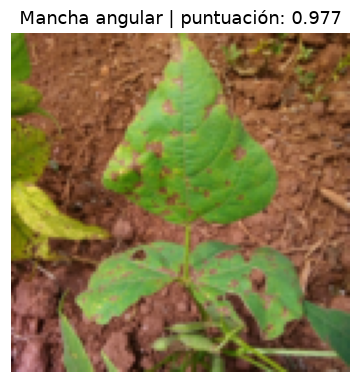

,Mancha angular,Roya del frijol,Hoja sana
0,0.9767,0.0233,0.0


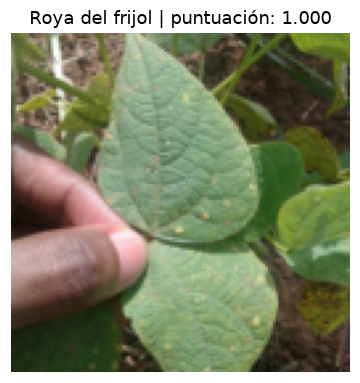

,Mancha angular,Roya del frijol,Hoja sana
0,0.0,1.0,0.0


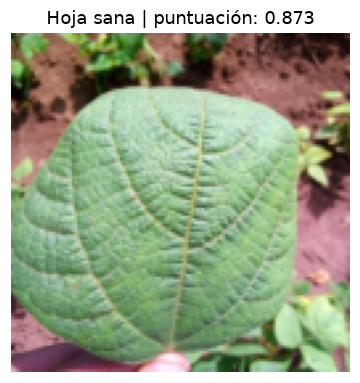

,Mancha angular,Roya del frijol,Hoja sana
0,0.0125,0.1145,0.873


,clase_real,prediccion,puntuacion,archivo
0,Mancha angular,Mancha angular,0.9767,angular_leaf_spot_test.0.jpg
1,Roya del frijol,Roya del frijol,1.0000,bean_rust_test.0.jpg
2,Hoja sana,Hoja sana,0.8730,healthy_test.0.jpg


La aplicación recibe una ruta de imagen y devuelve su clasificación


In [ ]:
demostracion = []
for etiqueta in range(3):
    indice = int(np.flatnonzero(y_test == etiqueta)[0])
    resultado = predecir_imagen(tabla_test.iloc[indice].ruta)
    demostracion.append({'clase_real': CLASES[etiqueta], 'prediccion': resultado['clase'],
                         'puntuacion': resultado['puntuacion'],
                         'archivo': Path(tabla_test.iloc[indice].ruta).name})
display(pd.DataFrame(demostracion).round(4))
print('La aplicación recibe una ruta de imagen y devuelve su clasificación')